# Modality prediction benchmark results

For the current state of the benchmark, see [OpenProblems task page](https://openproblems.bio/benchmarks/predict_modality)

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from funkyheatmappy import funky_heatmap
from funkyheatmappy.position_arguments import position_arguments
from matplotlib.colors import LinearSegmentedColormap, to_hex, to_rgb
from scipy.stats import kendalltau

PROJECT = Path("../data/")
LEADERBOARD = PROJECT / "OpenProblems_leaderboard"
FIGURES = PROJECT / "../figures"

TASKS = {"GEX → ADT": "gex_adt", "ATAC → GEX": "atac_gex"}  # OP has "direct" and "swap" tasks in the opposite direction. Here, we only take direct ones
YEARS = ["2021", "2022"]
METRICS = {
    "mean_pearson_per_cell": "Pearson per cell",
    "mean_spearman_per_cell": "Spearman per cell",
    "mean_pearson_per_gene": "Pearson per feature",
    "mean_spearman_per_gene": "Spearman per feature",
    "overall_pearson": "Overall Pearson",
    "overall_spearman": "Overall Spearman",
    "rmse": "RMSE",
    "mae": "MAE",
}
MINIMISED = {"rmse", "mae"}

# method: (row group, origin shown in the figures, year)
METHODS = {
    "ss_opm": ("Kaggle 2022 winners", "Kaggle 2022, 1st (O1M1)", "2022"),
    "senkin_tmp": ("Kaggle 2022 winners", "Kaggle 2022, 2nd (O2C1)", "2022"),
    "guanlab_dengkw_pm": ("NeurIPS 2021 competition", "NeurIPS 2021", "2021"),
    "novel": ("NeurIPS 2021 competition", "NeurIPS 2021", "2021"),
    "simple_mlp": ("NeurIPS 2021 competition", "NeurIPS 2021", "2021"),
    "babel": ("Published tools", "tool, 2021", "2021"),
    "scipenn": ("Published tools", "tool, 2022", "2022"),
    "scbutterfly": ("Published tools", "tool, 2024", "2024"),
    "cellmapper_linear": ("Published tools", "tool, 2025", "2025"),
    "cellmapper_scvi": ("Published tools", "tool, 2025", "2025"),
    "knnr_py": ("Baselines", "baseline", ""),
    "knnr_r": ("Baselines", "baseline", ""),
    "lm": ("Baselines", "baseline", ""),
    "mean_per_gene": ("Controls", "control", ""),
    "random_predict": ("Controls", "control", ""),
    "zeros": ("Controls", "control", ""),
    "solution": ("Controls", "control", ""),
}
ROW_GROUPS = ["Kaggle 2022 winners", "NeurIPS 2021 competition", "Published tools", "Baselines"]

pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

In [2]:
wide_all = pd.read_csv(LEADERBOARD / "results_wide.csv")
long_all = pd.read_csv(LEADERBOARD / "results_long.csv")
leaderboard = pd.read_csv(LEADERBOARD / "leaderboard.csv")

for table in (wide_all, long_all, leaderboard):
    table["paramset"] = table["paramset"].fillna("")

wide_all.groupby(["task", "status"]).size().unstack(fill_value=0)

status,execution error,not applicable,success
task,,,
ADT → GEX,0,8,44
ATAC → GEX,10,4,38
GEX → ADT,0,4,48
GEX → ATAC,0,6,46


CellMapper is benchmarked with five (scVI) and six (PCA/CCA) paramsets, we will only take the best hyperparameter set per input

In [ ]:
best_paramset = (leaderboard.sort_values("mean_score", ascending=False)
                 .drop_duplicates("method")
                 [["method", "paramset"]])

wide = wide_all.merge(best_paramset, on=["method", "paramset"])
wide = wide[wide["task"].isin(TASKS)].copy()
wide["year"] = wide["dataset"].str.extract(r"neurips(\d{4})")[0]
LABEL_RENAMES = {"SS-OPM": "SS-OPM (O1M1)", "senkin & tmp": "senkin & tmp (O2C1)"}
wide["method_label"] = wide["method_label"].replace(LABEL_RENAMES)

display(best_paramset[best_paramset["paramset"] != ""])

failures = wide_all[wide_all["task"].isin(TASKS) & ~wide_all["status"].isin(["success", "not applicable"])]
failures = failures[["dataset", "task", "method", "paramset", "status", "run_exit_codes"]]
# failures.to_csv(TABLES / "failures.csv", index=False)
failures

,method,paramset
4,cellmapper_scvi,cellmapper_gauss_all_genes
5,cellmapper_linear,cellmapper-pca


,dataset,task,method,paramset,status,run_exit_codes
80,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,cellmapper_linear,cellmapper-cca-hvg,execution error,[1]
81,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,cellmapper_linear,cellmapper-cca-hvg-gauss,execution error,[1]
86,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,cellmapper_scvi,cellmapper_gauss_hvg,execution error,[1]
87,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,cellmapper_scvi,cellmapper_gauss_hvg_log_cp10k,execution error,[1]
89,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,cellmapper_scvi,cellmapper_hnoca_hvg,execution error,[1]
184,openproblems_neurips2022/pbmc_multiome/swap,ATAC → GEX,cellmapper_linear,cellmapper-cca-hvg,execution error,[1]
185,openproblems_neurips2022/pbmc_multiome/swap,ATAC → GEX,cellmapper_linear,cellmapper-cca-hvg-gauss,execution error,[1]
190,openproblems_neurips2022/pbmc_multiome/swap,ATAC → GEX,cellmapper_scvi,cellmapper_gauss_hvg,execution error,[1]
191,openproblems_neurips2022/pbmc_multiome/swap,ATAC → GEX,cellmapper_scvi,cellmapper_gauss_hvg_log_cp10k,execution error,[1]
193,openproblems_neurips2022/pbmc_multiome/swap,ATAC → GEX,cellmapper_scvi,cellmapper_hnoca_hvg,execution error,[1]


# Figure 2 panels: per-cell Pearson per direct task and dataset year

Pearson's R was the flagship metric of the 2022 competition, so for the main figure we display it

/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:79: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['id' '2021' '2022' 'mean']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_color"]), "id_color"] = column_info["id"] # if nan, replace by id, except if text or image
/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:89: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['id' '2021' '2022' 'mean']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_size"]), "id_size"] = column_info["id"] # if nan, replace by id, except if text or image
/Users/vladi

Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': "Pearson's R per cell"} did not contain labels, inferring from the geom.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': "Pearson's R per cell", 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1']} did not contain size, inferring from the labels.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': "Pearson's R per cell", 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1'], 'size': [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0]} did not contain color, inferring from the palette.


/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/add_column_if_missing.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col_keys] = df[col_keys].fillna(col_values)


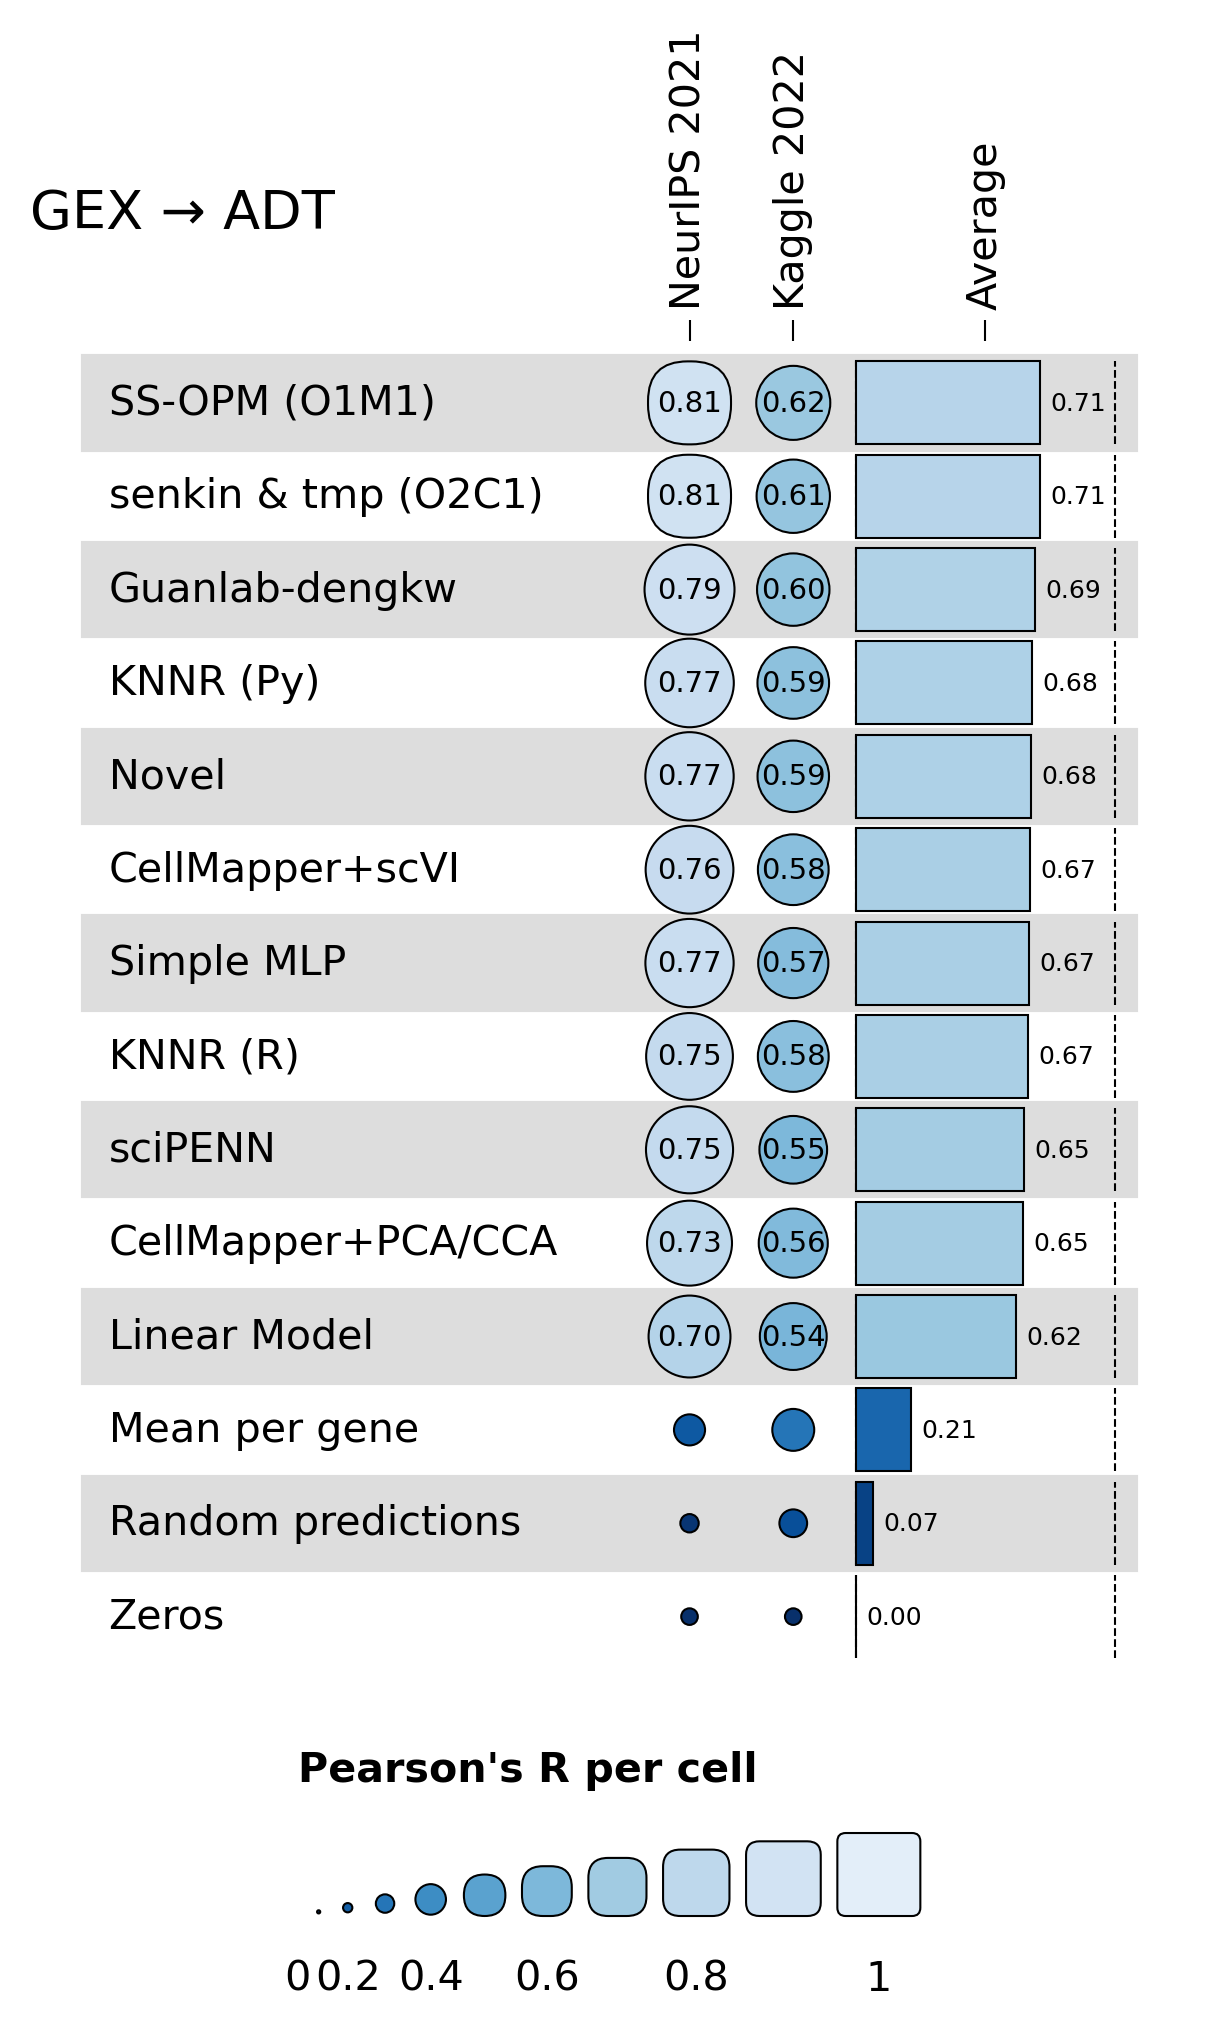

/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:79: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['id' '2021' '2022' 'mean']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_color"]), "id_color"] = column_info["id"] # if nan, replace by id, except if text or image
/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:89: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['id' '2021' '2022' 'mean']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_size"]), "id_size"] = column_info["id"] # if nan, replace by id, except if text or image
/Users/vladi

Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': "Pearson's R per cell"} did not contain labels, inferring from the geom.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': "Pearson's R per cell", 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1']} did not contain size, inferring from the labels.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': "Pearson's R per cell", 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1'], 'size': [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0]} did not contain color, inferring from the palette.


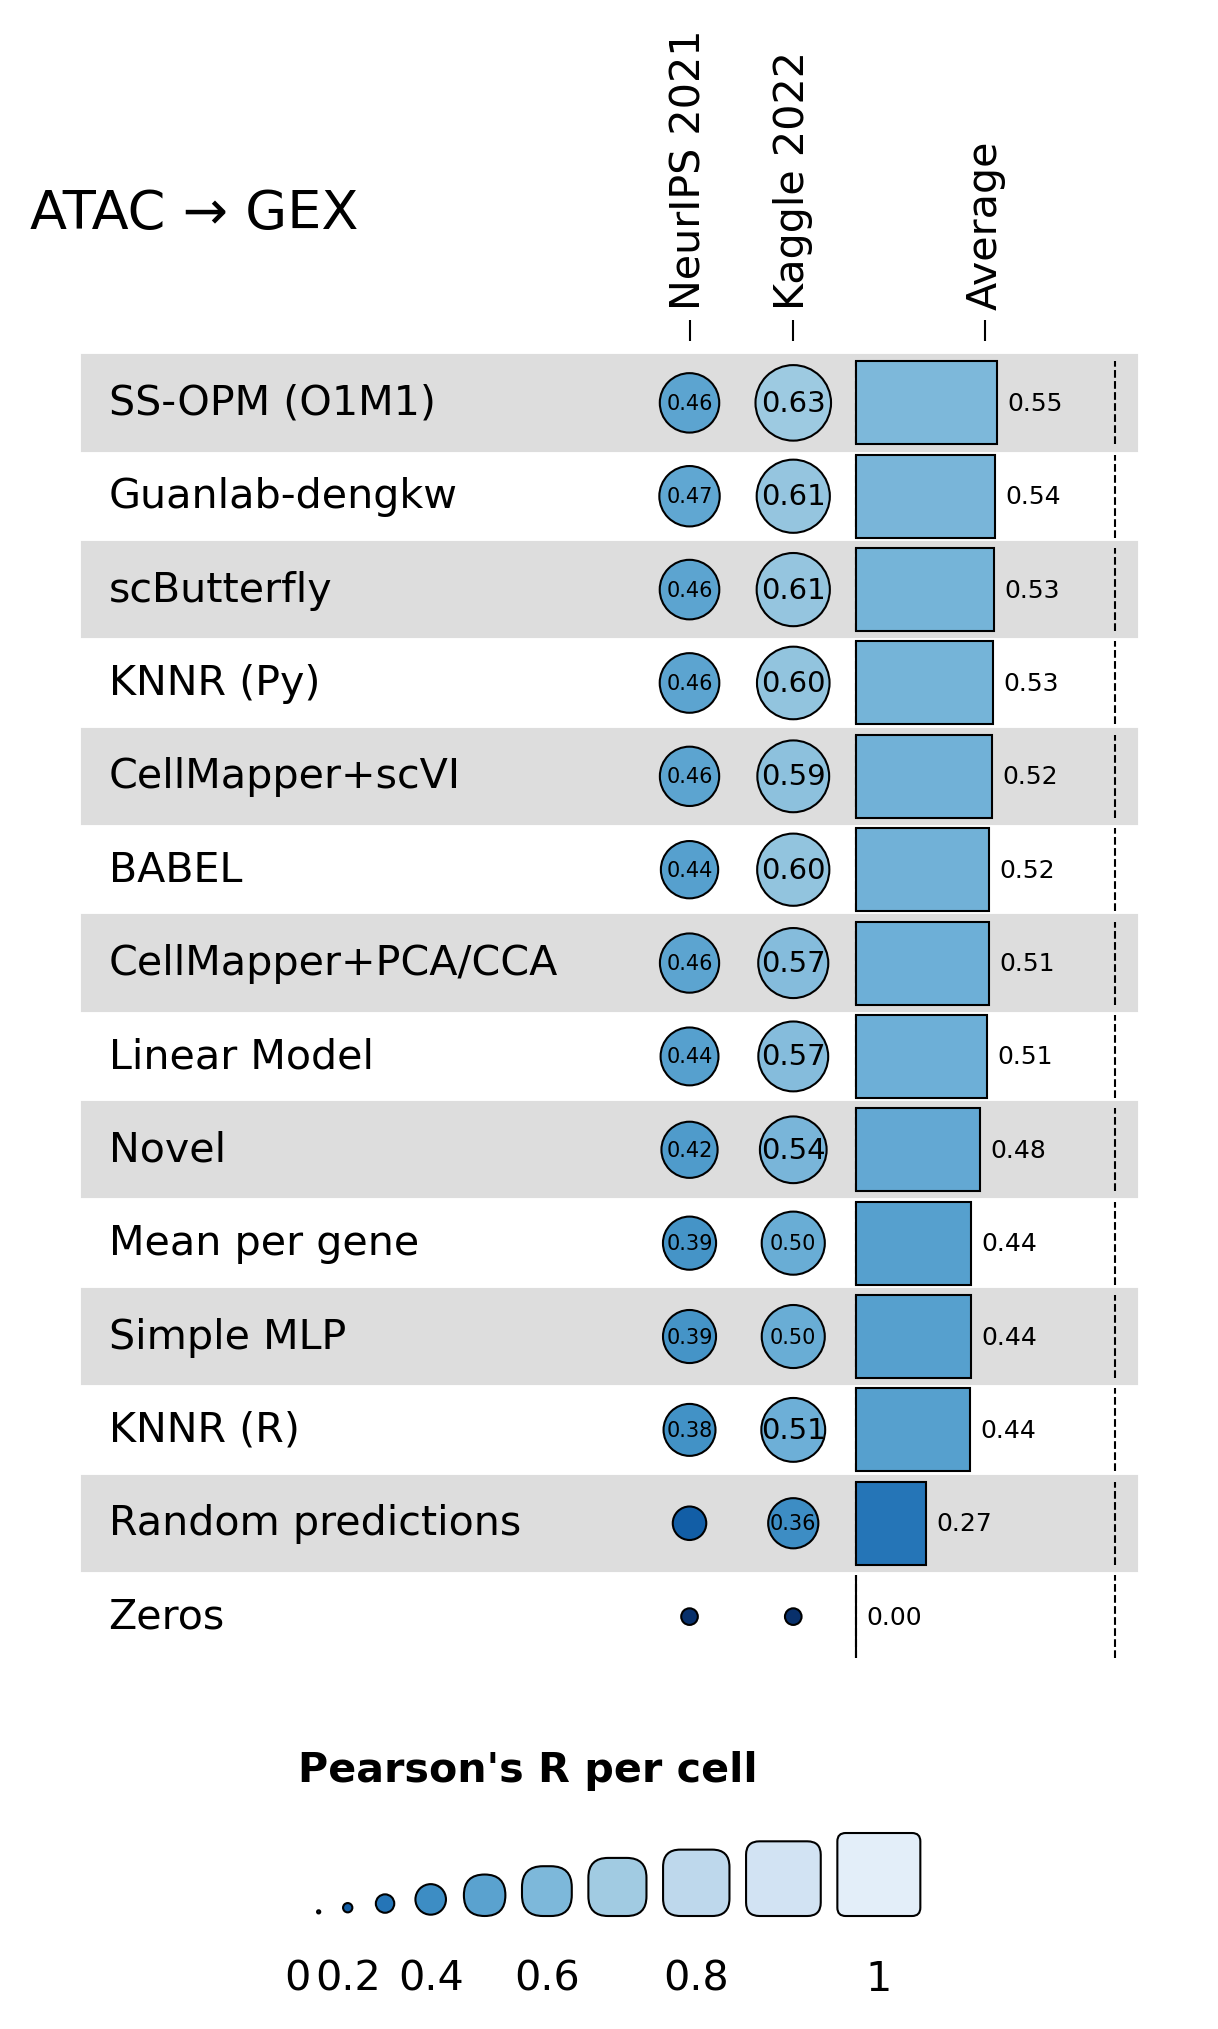

year,task,method,method_label,2021,2022,mean
0,GEX → ADT,ss_opm,SS-OPM (O1M1),0.811,0.615,0.713
1,GEX → ADT,senkin_tmp,senkin & tmp (O2C1),0.812,0.608,0.710
2,GEX → ADT,guanlab_dengkw_pm,Guanlab-dengkw,0.786,0.598,0.692
3,GEX → ADT,knnr_py,KNNR (Py),0.771,0.590,0.680
4,GEX → ADT,novel,Novel,0.768,0.588,0.678
5,GEX → ADT,cellmapper_scvi,CellMapper+scVI,0.762,0.580,0.671
6,GEX → ADT,simple_mlp,Simple MLP,0.767,0.574,0.671
7,GEX → ADT,knnr_r,KNNR (R),0.751,0.581,0.666
8,GEX → ADT,scipenn,sciPENN,0.755,0.547,0.651
9,GEX → ADT,cellmapper_linear,CellMapper+PCA/CCA,0.732,0.562,0.647


In [4]:
from funkyheatmappy.verify_palettes import default_palettes

WIDTHS = {"label": 5, "2021": 0.8, "2022": 0.8, "mean": 2.5}  # plot units
COL_SPACE = 0.2  # gap before every column, including the first
ROW_HEIGHT = 0.8
ROW_STEP = ROW_HEIGHT + 0.1  # row_height + row_space
COLUMN_NAMES = {"2021": "NeurIPS 2021", "2022": "Kaggle 2022", "mean": "Average"}
VALUE_COLUMNS = [*YEARS, "mean"]
PALETTE = default_palettes["numerical"]["Blues"]  # what funkyheatmappy assigns to the first numerical column; used for text colour


def text_colour(palette, score):
    # white on dark marks, black on light ones (relative luminance of the mark's colour)
    red, green, blue = to_rgb(palette[int(round(score * 100))])
    return "white" if 0.2126 * red + 0.7152 * green + 0.0722 * blue < 0.45 else "black"


def column_starts():
    # mirrors funkyheatmappy.calculate_column_positions without groups: every column is preceded by col_space
    x, starts = 0.0, {}
    for column in ["label", *VALUE_COLUMNS]:
        x += COL_SPACE
        starts[column] = x
        x += WIDTHS[column]
    return starts


def match_legend_scale(figure, mark_size=1.0):
    # legends are drawn in their own axes with 1 unit per full mark; scale them so that unit equals a full mark on the plot
    main, *legend_axes = figure.get_axes()
    for _ in range(2):  # the constrained layout settles after a draw
        figure.canvas.draw()
        main.apply_aspect()
        box = main.get_position(original=False)
        units_per_inch = np.ptp(main.get_xlim()) / (box.width * figure.get_figwidth()) / mark_size
        for legend in legend_axes:  # the y range spans the legend band; the box then shrinks around the content in x
            height = legend.get_position(original=True).height * figure.get_figheight() * units_per_inch
            y = np.mean(legend.get_ylim())
            legend.set_ylim(y - height / 2, y + height / 2)


def pearson_table(task):
    rows = wide[(wide["task"] == task) & (wide["method"] != "solution") & (wide["status"] != "not applicable")]
    rows = rows.assign(score=rows["mean_pearson_per_cell"].where(rows["status"] == "success"))
    table = rows.pivot_table(index="method", columns="year", values="score", dropna=False).reset_index()
    table["method_label"] = table["method"].map(rows.drop_duplicates("method").set_index("method")["method_label"])
    table["mean"] = table[YEARS].mean(axis=1)
    return table.sort_values("mean", ascending=False).reset_index(drop=True)


def plot_pearson(table, task):
    data = pd.DataFrame({"id": table["method_label"], **{column: table[column] for column in VALUE_COLUMNS}})
    column_info = pd.DataFrame({
        "id": ["id", *VALUE_COLUMNS],
        "name": ["", *(COLUMN_NAMES[column] for column in VALUE_COLUMNS)],
        "geom": ["text"] + ["funkyrect"] * len(YEARS) + ["bar"],
        "palette": [np.nan] + ["score"] * len(VALUE_COLUMNS),
        "width": [WIDTHS["label"], *(WIDTHS[column] for column in VALUE_COLUMNS)],
        "legend": [False] * (len(VALUE_COLUMNS) + 1),
        "ha": [0.0] + [0.5] * len(VALUE_COLUMNS),
    }).set_index("id", drop=False)
    with plt.rc_context({"figure.dpi": 300, "font.size": 12}):
        figure = funky_heatmap(
            data, column_info=column_info, scale_column=False,
            legends=[{"palette": "score", "enabled": True, "geom": "funkyrect", "title": "Pearson's R per cell"}],
            position_args={"row_height": ROW_HEIGHT, "row_space": 0.1, "row_bigspace": 0.5, "col_width": 0.7, "col_space": COL_SPACE,
                           "col_bigspace": 0.5, "col_annot_offset": 0.3, "col_annot_angle": 90, "expand_xmin": 0,
                           "expand_xmax": 2, "expand_ymin": 0, "expand_ymax": 0},
        )
        ax = figure.get_axes()[0]
        starts = column_starts()
        centres = {column: starts[column] + WIDTHS[column] / 2 for column in VALUE_COLUMNS}
        label_centres = {COLUMN_NAMES[column]: x for column, x in centres.items()}
        for text in ax.texts:  # funkyheatmap anchors rotated labels at the column's right edge; recentre them
            if text.get_text() in label_centres:
                text.set_x(label_centres[text.get_text()])
                text.set_ha("center")
                text.set_va("bottom")

        for i, row in data.iterrows():
            y = -i * ROW_STEP - ROW_STEP
            for year in YEARS:
                x = centres[year]
                if pd.isna(row[year]):
                    ax.text(x, y, "failed", va="center", ha="center", fontsize=5, color="#666666")
                elif row[year] > 0.3:
                    ax.text(x, y, f"{row[year]:.2f}", va="center", ha="center",
                            fontsize=7 if row[year] > 0.5 else 5, color=text_colour(PALETTE, row[year]))
            if not pd.isna(row["mean"]):  # bar runs from the column's left edge; print the value just past its end
                ax.text(starts["mean"] + row["mean"] * WIDTHS["mean"] + 0.1, y, f"{row['mean']:.2f}",
                        va="center", ha="left", fontsize=6, color="black")
        ax.set_title(task, fontsize=13, loc="left")
        match_legend_scale(figure, mark_size=min(ROW_HEIGHT, *(WIDTHS[year] for year in YEARS)))  # a full funkyrect fills the cell
    return figure


pearson_tables = []
for task, key in TASKS.items():
    table = pearson_table(task)
    pearson_tables.append(table.assign(task=task))
    figure = plot_pearson(table, task)
    for suffix in ("png", "pdf"):
        figure.savefig(FIGURES / f"pearson_per_cell_{key}.{suffix}", bbox_inches="tight", dpi=300)
    plt.show()

pearson = pd.concat(pearson_tables)[["task", "method", "method_label", *YEARS, "mean"]]
# pearson.to_csv(TABLES / "pearson_per_cell_direct_tasks.csv", index=False)
pearson


# Every metric

The website's scaled scores: each metric min-max scaled between the control methods per dataset (0 = worst control, 1 = solution) and clipped to [0, 1]. Per task they are averaged over the two datasets; a failed run counts as 0 and a task a method cannot run is left empty. Rows are ordered within their group by the mean rank over the tasks they cover.

In [5]:
def scaled_score_grid():
    # every (dataset, method, metric) of the non-control methods on the tasks they apply to
    methods = wide[~wide["is_control"]]
    grid = methods[["dataset", "task", "method", "paramset", "status", "year"]].merge(
        pd.DataFrame({"metric": list(METRICS)}), how="cross")
    grid = grid.merge(long_all[["dataset", "method", "paramset", "metric", "scaled_score"]],
                      on=["dataset", "method", "paramset", "metric"], how="left")
    grid = grid[grid["status"] != "not applicable"]
    grid.loc[grid["status"] != "success", "scaled_score"] = 0.0
    return grid


grid = scaled_score_grid()
task_score = grid.pivot_table(index="method", columns="task", values="scaled_score").reindex(columns=list(TASKS))
year_score = grid.pivot_table(index="method", columns=["task", "year"], values="scaled_score")
metric_score = grid.pivot_table(index="method", columns=["task", "metric"], values="scaled_score")

methods = wide[~wide["is_control"]]
summary = pd.DataFrame(index=task_score.index)
summary["label"] = methods.drop_duplicates("method").set_index("method")["method_label"]
summary["group"] = [METHODS[method][0] for method in summary.index]
summary["year"] = [METHODS[method][2] for method in summary.index]
summary["datasets"] = methods.groupby("method")["status"].agg(
    lambda status: f"{(status == 'success').sum()}/{(status != 'not applicable').sum()}")
summary["mean_task_rank"] = task_score.rank(ascending=False, method="min").mean(axis=1)
summary["duration"] = methods[methods["status"] == "success"].groupby("method")["duration_secs"].mean().map(
    lambda seconds: f"{seconds / 60:.0f} min" if seconds < 3600 else f"{seconds / 3600:.1f} h")
for task, key in TASKS.items():
    for year in YEARS:
        summary[f"{key}_{year}"] = year_score.get((task, year))
    for metric, name in METRICS.items():
        summary[f"{key}_{metric}"] = metric_score.get((task, metric))
summary["group"] = pd.Categorical(summary["group"], categories=ROW_GROUPS, ordered=True)
summary = summary.sort_values(["group", "mean_task_rank"])
# summary.to_csv(TABLES / "funkyheatmap_input.csv")
summary[["label", "group", "datasets", "mean_task_rank", *[f"{key}_{year}" for key in TASKS.values() for year in YEARS]]]

,label,group,datasets,mean_task_rank,gex_adt_2021,gex_adt_2022,atac_gex_2021,atac_gex_2022
method,,,,,,,,
ss_opm,SS-OPM (O1M1),Kaggle 2022 winners,4/4,1.5,0.665,0.527,0.276,0.361
senkin_tmp,senkin & tmp (O2C1),Kaggle 2022 winners,2/2,2.0,0.654,0.521,NaN,NaN
guanlab_dengkw_pm,Guanlab-dengkw,NeurIPS 2021 competition,4/4,2.0,0.637,0.531,0.287,0.353
simple_mlp,Simple MLP,NeurIPS 2021 competition,4/4,8.0,0.603,0.508,0.209,0.255
novel,Novel,NeurIPS 2021 competition,4/4,9.0,0.541,0.515,0.242,0.294
scbutterfly,scButterfly,Published tools,2/2,3.0,NaN,NaN,0.274,0.348
cellmapper_scvi,CellMapper+scVI,Published tools,4/4,6.0,0.550,0.523,0.274,0.339
cellmapper_linear,CellMapper+PCA/CCA,Published tools,4/4,7.0,0.561,0.508,0.276,0.325
babel,BABEL,Published tools,2/2,8.0,NaN,NaN,0.239,0.321


/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:79: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['label' '2021' '2022' 'average' 'mean_pearson_per_cell'
 'mean_spearman_per_cell' 'mean_pearson_per_gene' 'mean_spearman_per_gene'
 'overall_pearson' 'overall_spearman' 'rmse' 'mae' 'duration']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_color"]), "id_color"] = column_info["id"] # if nan, replace by id, except if text or image
/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:89: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['label' '2021' '2022' 'average' 'mean_pearson_per_cell'
 'mean_spearman_per_cell' 'mean_pears

Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': 'Scaled score'} did not contain labels, inferring from the geom.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': 'Scaled score', 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1']} did not contain size, inferring from the labels.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': 'Scaled score', 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1'], 'size': [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0]} did not contain color, inferring from the palette.


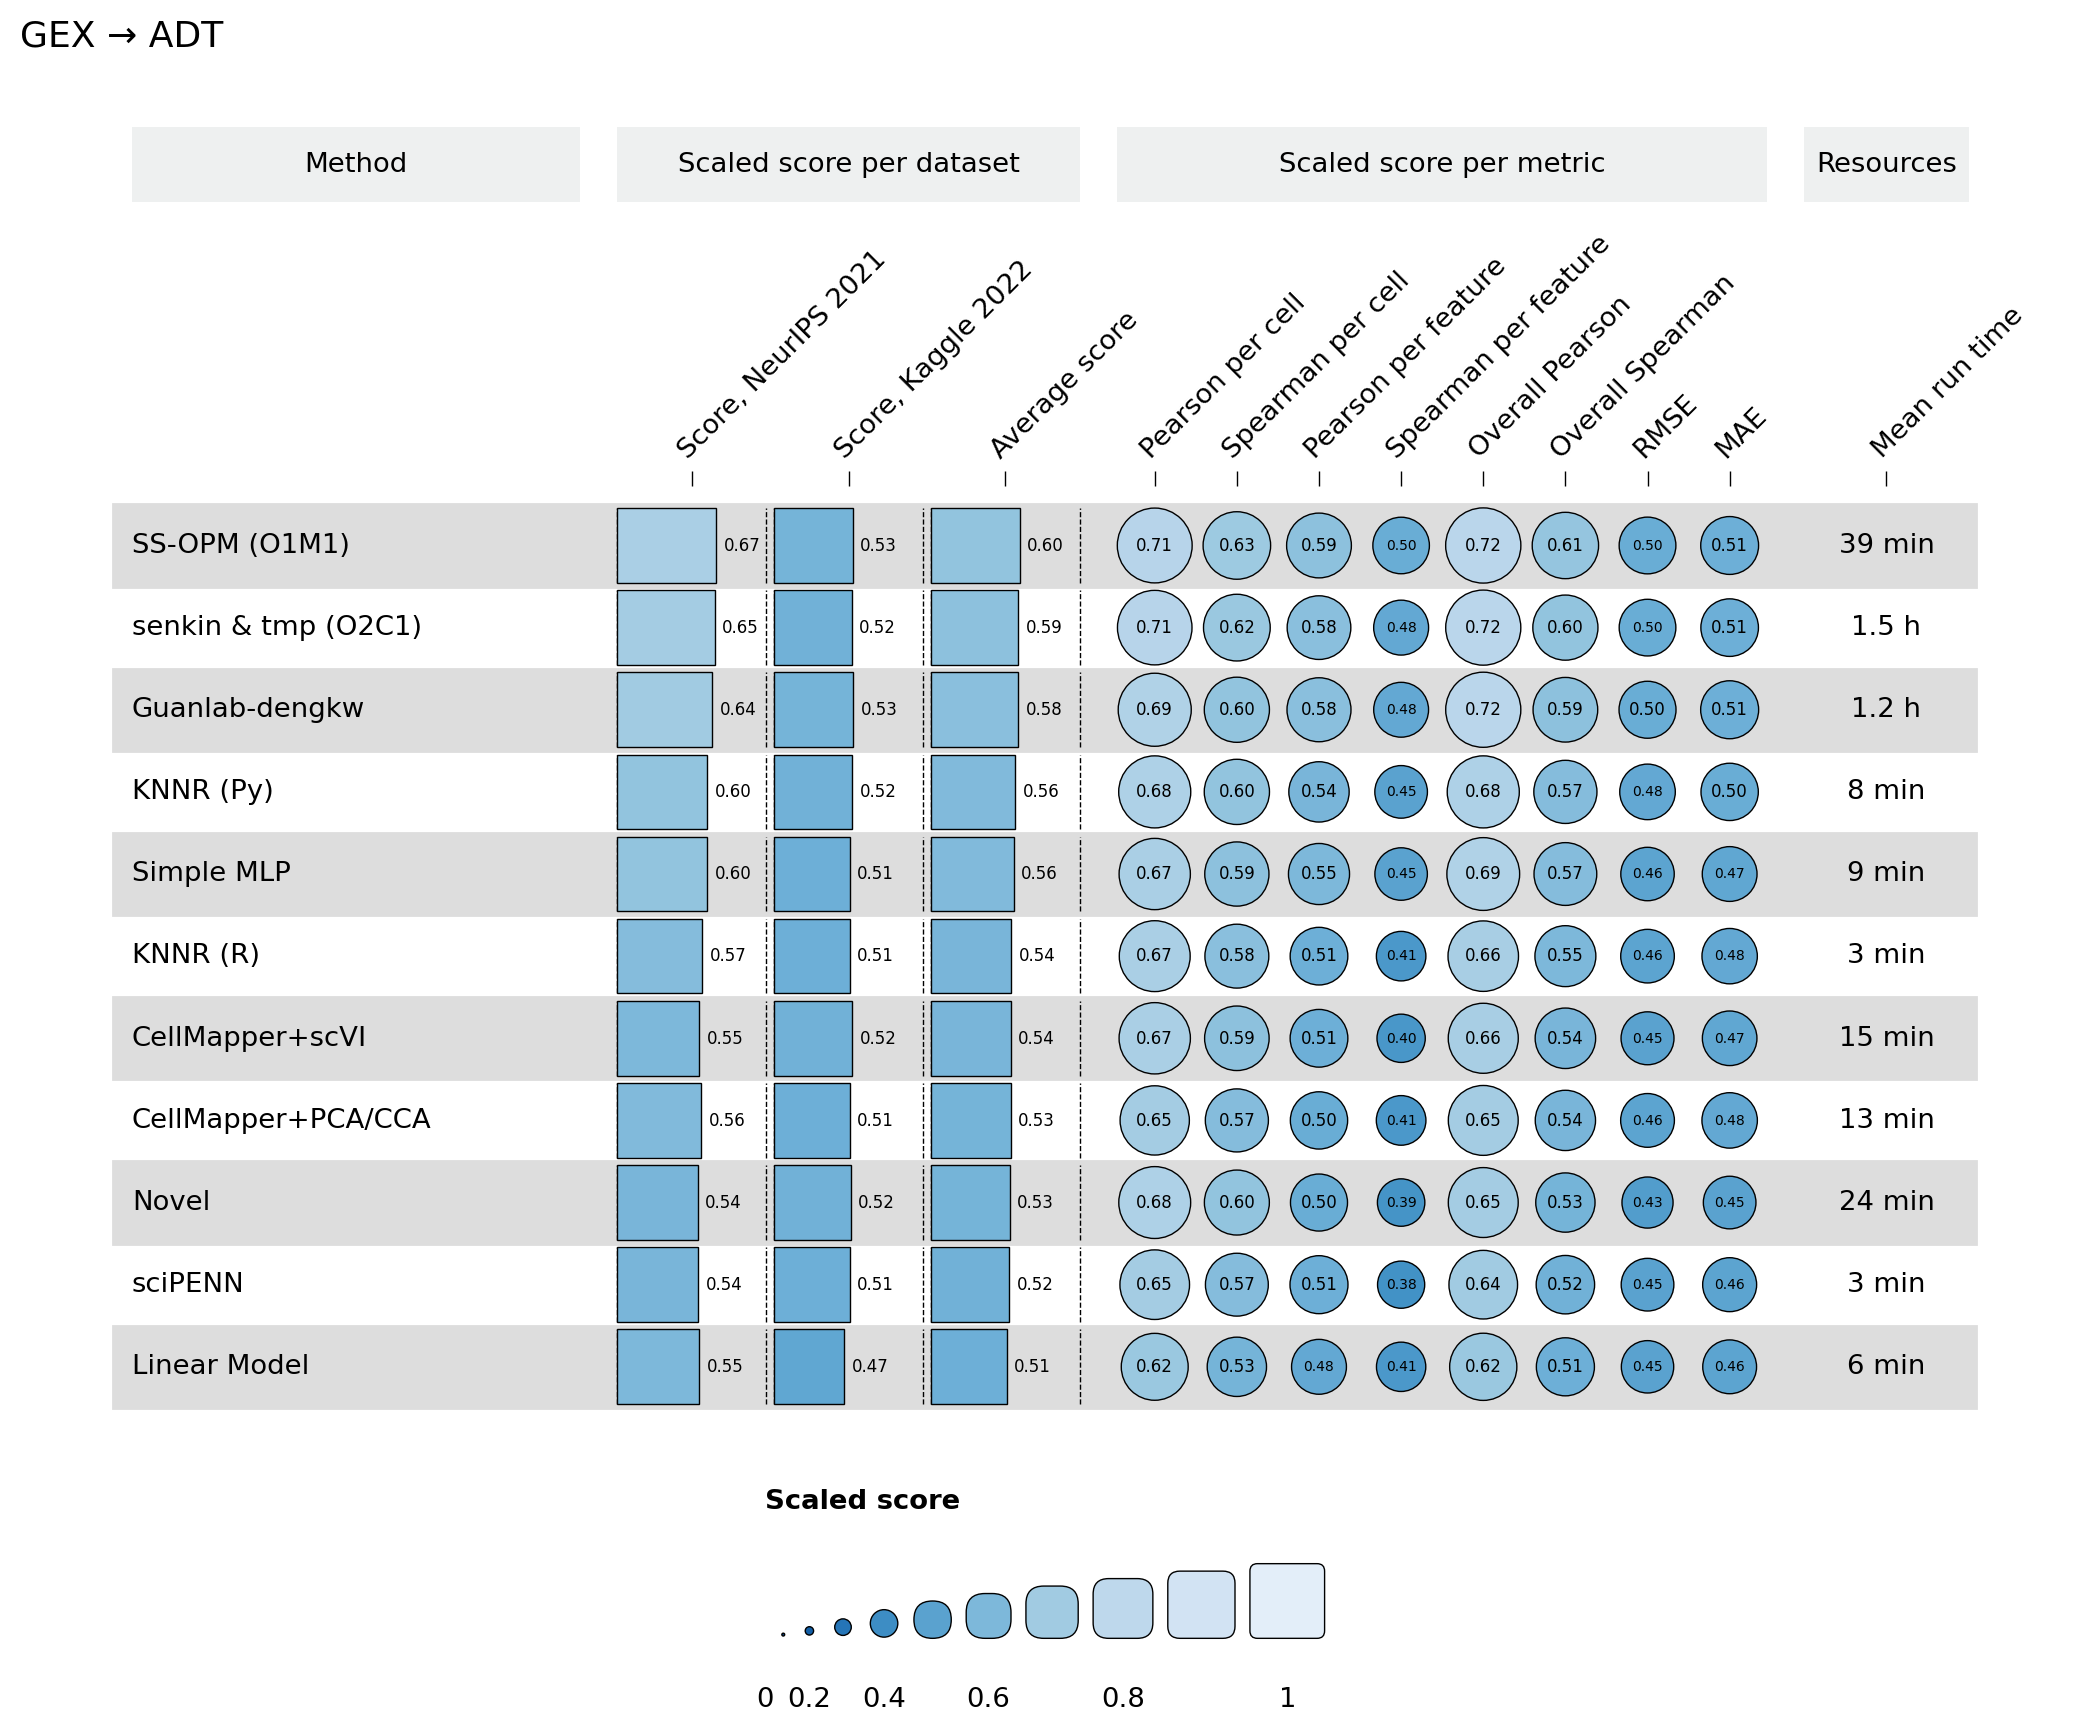

/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:79: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['label' '2021' '2022' 'average' 'mean_pearson_per_cell'
 'mean_spearman_per_cell' 'mean_pearson_per_gene' 'mean_spearman_per_gene'
 'overall_pearson' 'overall_spearman' 'rmse' 'mae' 'duration']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  column_info.loc[pd.isna(column_info["id_color"]), "id_color"] = column_info["id"] # if nan, replace by id, except if text or image
/Users/vladimir.shitov/miniconda3/envs/patpy/lib/python3.11/site-packages/funkyheatmappy/verify_column_info.py:89: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['label' '2021' '2022' 'average' 'mean_pearson_per_cell'
 'mean_spearman_per_cell' 'mean_pears

Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': 'Scaled score'} did not contain labels, inferring from the geom.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': 'Scaled score', 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1']} did not contain size, inferring from the labels.
Legend {'palette': 'score', 'enabled': True, 'geom': 'funkyrect', 'title': 'Scaled score', 'labels': ['0', '', '0.2', '', '0.4', '', '0.6', '', '0.8', '', '1'], 'size': [0.0, 0.1, 0.2, 0.30000000000000004, 0.4, 0.5, 0.6000000000000001, 0.7000000000000001, 0.8, 0.9, 1.0]} did not contain color, inferring from the palette.


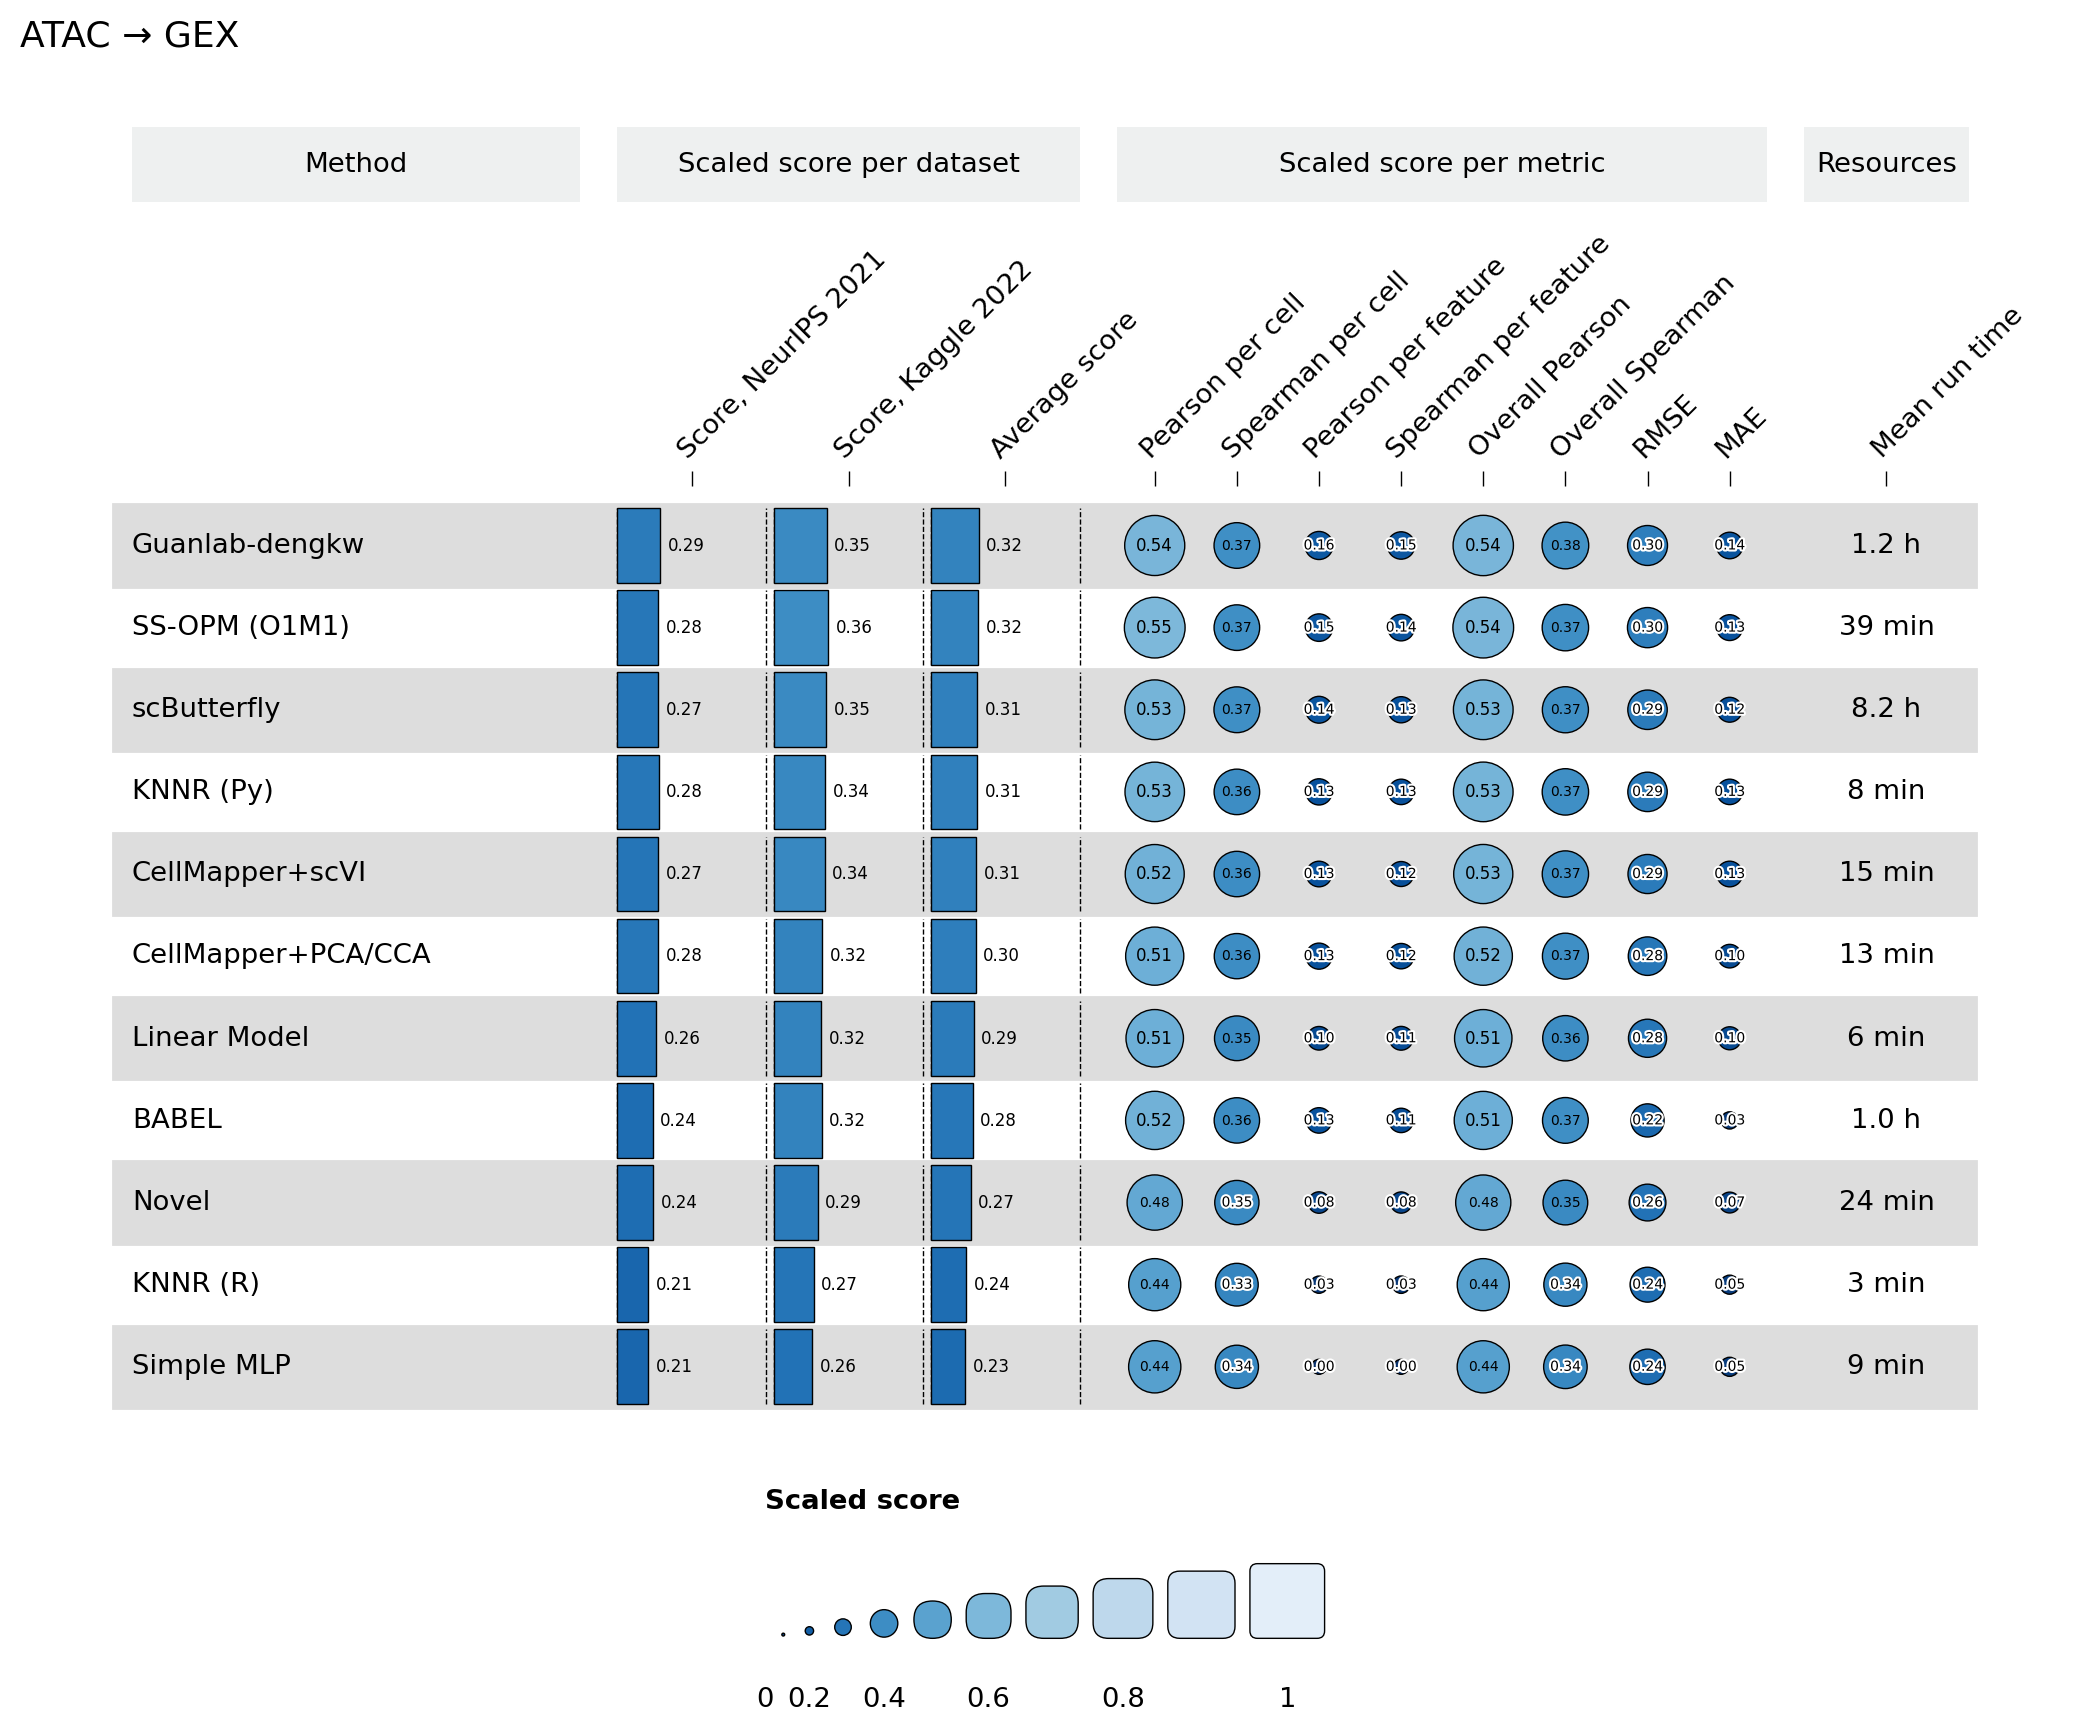

In [6]:
from funkyheatmappy.verify_palettes import default_palettes
from matplotlib.patheffects import withStroke

PALETTE = default_palettes["numerical"]["Blues"]  # funkyheatmappy's default for numerical columns; used for text colour
BAR_NAMES = {"2021": "Score, NeurIPS 2021", "2022": "Score, Kaggle 2022", "average": "Average score"}
POSITIONS = {"row_height": 1, "row_space": 0.1, "col_space": 0.1, "col_bigspace": 0.5}
HALO = [withStroke(linewidth=1.5, foreground="white")]  # keeps numbers legible on marks smaller than the text


def ramp(*colours):
    cmap = LinearSegmentedColormap.from_list("ramp", list(colours))
    return [to_hex(cmap(value)) for value in np.linspace(0, 1, 101)]


def text_colour(palette, score):
    # white on dark marks, black on light ones (relative luminance of the mark's colour)
    red, green, blue = to_rgb(palette[int(round(score * 100))])
    return "white" if 0.2126 * red + 0.7152 * green + 0.0722 * blue < 0.45 else "black"


def column_bounds(column_info):
    # mirrors funkyheatmappy.calculate_column_positions: col_space between columns, col_bigspace between groups
    x, bounds, previous_group = 0.0, {}, None
    for column_id, column in column_info.iterrows():
        x += POSITIONS["col_bigspace"] if previous_group not in (None, column["group"]) else POSITIONS["col_space"]
        bounds[column_id] = (x, x + column["width"])
        x += column["width"]
        previous_group = column["group"]
    return bounds


def anchor_column_labels(ax, column_info, bounds):
    # funkyheatmap places rotated labels by their bounding box, which shifts them right; anchor the text start at the tick
    centres = {name: sum(bounds[column_id]) / 2 for column_id, name in column_info["name"].items() if name}
    for text in ax.texts:
        if text.get_text() in centres and text.get_rotation():
            text.set_x(centres[text.get_text()])
            text.set_rotation_mode("anchor")
            text.set_ha("left")
            text.set_va("bottom")


def match_legend_scale(figure):
    # legends are drawn in their own axes; give them the same data-units-per-inch as the main plot
    main, *legend_axes = figure.get_axes()
    for _ in range(2):  # the constrained layout settles after a draw
        figure.canvas.draw()
        main.apply_aspect()
        box = main.get_position(original=False)
        units_per_inch = np.ptp(main.get_xlim()) / (box.width * figure.get_figwidth())
        for legend in legend_axes:  # the y range spans the legend band; the box then shrinks around the content in x
            height = legend.get_position(original=True).height * figure.get_figheight() * units_per_inch
            y = np.mean(legend.get_ylim())
            legend.set_ylim(y - height / 2, y + height / 2)


def task_summary(key):
    # methods that apply to the task, sorted by their average scaled score over its two datasets
    scores = summary[[f"{key}_{year}" for year in YEARS]].dropna(how="all")
    table = summary.loc[scores.index].copy()
    table["average"] = scores.mean(axis=1)
    return table.sort_values("average", ascending=False)


def plot_task(task, key):
    table = task_summary(key)
    data = pd.DataFrame({"id": table.index, "label": table["label"], "duration": table["duration"].fillna("")})
    column_rows = [("label", "", "text", "method", np.nan, 6, 0.0)]
    for column in BAR_NAMES:
        data[column] = table[f"{key}_{column}" if column in YEARS else column].to_numpy()
        column_rows.append((column, BAR_NAMES[column], "bar", "scores", "score", 2, 0.5))
    for metric, name in METRICS.items():
        data[metric] = table[f"{key}_{metric}"].to_numpy()
        column_rows.append((metric, name, "funkyrect", "metrics", "score", 1, 0.5))
    column_rows.append(("duration", "Mean run time", "text", "resources", np.nan, 2.2, 0.5))
    column_info = pd.DataFrame(column_rows, columns=["id", "name", "geom", "group", "palette", "width", "ha"]).set_index("id", drop=False)
    column_info["legend"] = False
    column_groups = pd.DataFrame({
        "group": ["method", "scores", "metrics", "resources"],
        "palette": ["overall"] * 4,
        "level1": ["Method", "Scaled score per dataset", "Scaled score per metric", "Resources"],
    })
    with plt.rc_context({"figure.dpi": 200, "font.size": 11}):
        figure = funky_heatmap(
            data, column_info=column_info, column_groups=column_groups, scale_column=False,
            palettes={"overall": ramp("#ffffff", "#7f8c8d")},  # "score" is left out on purpose: the library default is used
            legends=[{"palette": "score", "enabled": True, "geom": "funkyrect", "title": "Scaled score"}],
            position_args=position_arguments(col_annot_offset=3.5, col_annot_angle=45, expand_xmax=3, **POSITIONS),
        )
        ax = figure.get_axes()[0]
        bounds = column_bounds(column_info)
        anchor_column_labels(ax, column_info, bounds)
        row_step = POSITIONS["row_height"] + POSITIONS["row_space"]
        for i, (_, row) in enumerate(data.iterrows()):
            y = -(i + 1) * row_step
            for column in BAR_NAMES:  # bars start at the column's left edge; print the value just past their end
                value = row[column]
                if not pd.isna(value):
                    xmin, xmax = bounds[column]
                    ax.text(xmin + value * (xmax - xmin) + 0.1, y, f"{value:.2f}", ha="left", va="center", fontsize=6)
            for metric in METRICS:
                value = row[metric]
                if pd.isna(value):
                    continue
                small = value < 0.35  # the mark is smaller than the text, which spills onto the white background
                ax.text(sum(bounds[metric]) / 2, y, f"{value:.2f}", ha="center", va="center",
                        fontsize=5 if small or value <= 0.5 else 6,
                        color="black" if small else text_colour(PALETTE, value), path_effects=HALO if small else None)
        ax.set_title(task, fontsize=13, loc="left")
        match_legend_scale(figure)
    return figure


for task, key in TASKS.items():
    figure = plot_task(task, key)
    for suffix in ("png", "pdf"):
        figure.savefig(FIGURES / f"openproblems_{key}.{suffix}", bbox_inches="tight", dpi=200)
    plt.show()


# Metric agreement

Per dataset, Kendall τ between the ranking of the non-control methods by per-cell Pearson and by every other metric (RMSE and MAE negated), then averaged. SS-OPM is left out of the comparisons with the two Spearman metrics affected by the bug.

In [ ]:
def metric_rank_agreement():
    rows = []
    methods = wide[~wide["is_control"] & (wide["status"] == "success")]
    for dataset, group in methods.groupby("dataset"):
        for metric in METRICS:
            if metric == "mean_pearson_per_cell":
                continue
            values = -group[metric] if metric in MINIMISED else group[metric]
            rows.append({"dataset": dataset, "task": group["task"].iloc[0], "metric": METRICS[metric],
                         "n_methods": len(group),
                         "kendall_tau": kendalltau(group["mean_pearson_per_cell"], values).statistic,
                         "top_by_pearson_per_cell": group.loc[group["mean_pearson_per_cell"].idxmax(), "method"],
                         "top_by_metric": group.loc[values.idxmax(), "method"]})
    return pd.DataFrame(rows)


agreement = metric_rank_agreement()
# agreement.to_csv(TABLES / "metric_rank_agreement.csv", index=False)
agreement_summary = agreement.groupby("metric")["kendall_tau"].agg(mean_tau="mean", lowest_tau="min").join(
    agreement.pivot_table(index="metric", columns="task", values="kendall_tau")).sort_values("mean_tau", ascending=False)
agreement_summary.round(2)

,mean_tau,lowest_tau,ATAC → GEX,GEX → ADT
metric,,,,
Spearman per cell,0.80,0.60,0.71,0.89
Overall Pearson,0.80,0.53,0.96,0.64
Overall Spearman,0.71,0.55,0.76,0.67
Spearman per feature,0.63,0.42,0.80,0.45
Pearson per feature,0.60,0.31,0.82,0.38
RMSE,0.54,0.09,0.80,0.27
MAE,0.47,0.07,0.69,0.26


In [10]:
agreement

,dataset,task,metric,n_methods,kendall_tau,top_by_pearson_per_cell,top_by_metric
0,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,Spearman per cell,11,0.855,senkin_tmp,ss_opm
1,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,Pearson per feature,11,0.455,senkin_tmp,ss_opm
2,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,Spearman per feature,11,0.491,senkin_tmp,ss_opm
3,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,Overall Pearson,11,0.527,senkin_tmp,senkin_tmp
4,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,Overall Spearman,11,0.550,senkin_tmp,ss_opm
5,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,RMSE,11,0.455,senkin_tmp,senkin_tmp
6,openproblems_neurips2021/bmmc_cite/normal,GEX → ADT,MAE,11,0.455,senkin_tmp,ss_opm
7,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,Spearman per cell,11,0.600,guanlab_dengkw_pm,guanlab_dengkw_pm
8,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,Pearson per feature,11,0.745,guanlab_dengkw_pm,guanlab_dengkw_pm
9,openproblems_neurips2021/bmmc_multiome/swap,ATAC → GEX,Spearman per feature,11,0.782,guanlab_dengkw_pm,guanlab_dengkw_pm


**Ranks per metric:** the rank of every non-control method under every metric (1 = best), per dataset and averaged
over the datasets of each task.

In [8]:
ranked = wide[~wide["is_control"] & (wide["status"] == "success")].copy()
for metric in METRICS:
    values = -ranked[metric] if metric in MINIMISED else ranked[metric]
    ranked[metric] = values.groupby(ranked["dataset"]).rank(ascending=False, method="min")
ranks_per_dataset = ranked[["dataset", "task", "method", *METRICS]].rename(columns=METRICS)
ranks_per_task = ranks_per_dataset.groupby(["task", "method"])[list(METRICS.values())].mean()
# ranks_per_dataset.to_csv(TABLES / "metric_ranks_per_dataset.csv", index=False)
# ranks_per_task.to_csv(TABLES / "metric_ranks_per_task.csv")
for task in TASKS:
    display(ranks_per_task.loc[task].sort_values("Pearson per cell").round(1).style.set_caption(task))

,Pearson per cell,Spearman per cell,Pearson per feature,Spearman per feature,Overall Pearson,Overall Spearman,RMSE,MAE
method,,,,,,,,
senkin_tmp,1.500000,2.000000,4.000000,4.500000,2.500000,3.000000,4.500000,5.000000
ss_opm,1.500000,1.000000,2.500000,1.500000,2.000000,1.500000,4.500000,4.000000
guanlab_dengkw_pm,3.000000,4.000000,2.000000,2.000000,2.000000,2.000000,3.500000,4.000000
knnr_py,4.000000,3.000000,6.000000,4.500000,5.500000,4.000000,2.500000,2.500000
novel,5.000000,5.000000,8.000000,8.000000,7.000000,8.000000,10.500000,10.500000
cellmapper_scvi,7.000000,6.000000,6.500000,7.000000,7.000000,6.500000,6.000000,5.500000
simple_mlp,7.000000,7.500000,6.000000,6.000000,5.500000,5.500000,7.000000,6.500000
knnr_r,7.500000,7.500000,8.000000,8.000000,7.000000,7.000000,6.500000,5.500000
scipenn,9.000000,9.500000,5.500000,7.000000,10.000000,10.000000,7.000000,8.000000


,Pearson per cell,Spearman per cell,Pearson per feature,Spearman per feature,Overall Pearson,Overall Spearman,RMSE,MAE
method,,,,,,,,
guanlab_dengkw_pm,2.000000,3.000000,1.000000,1.000000,1.500000,2.500000,1.500000,1.000000
scbutterfly,2.500000,2.500000,4.000000,3.000000,3.000000,5.000000,3.500000,5.000000
ss_opm,2.500000,4.000000,2.000000,2.000000,3.000000,3.000000,3.500000,3.000000
knnr_py,3.000000,4.500000,4.000000,4.500000,3.000000,2.500000,3.000000,4.000000
cellmapper_scvi,5.500000,5.000000,6.500000,6.000000,5.000000,3.500000,5.000000,3.000000
babel,6.500000,4.000000,6.000000,7.500000,6.500000,6.500000,9.500000,10.500000
cellmapper_linear,6.500000,5.000000,4.500000,4.500000,6.500000,5.000000,4.500000,5.000000
lm,7.500000,8.000000,8.000000,7.500000,7.500000,8.000000,7.000000,6.500000
novel,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,8.500000,8.000000
